🧱 Cell 1: Project Metadata & Overview:-
# DA-001: Enterprise Retail Sales Performance Analysis
### Capstone Analytics Pipeline & Tactical Diagnostics Engine
* **Course Code:** DA-001 (Retail & Sales Analytics)
* **Execution Timeline:** 4-Day High-Velocity Sprints
* **Objective:** Clean transaction-level enterprise retail data, calculate core financial KPIs, map multi-dimensional breakdowns, and synthesize evidence-based inventory recommendations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure publication-quality layout styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

# Ingest raw noisy transaction matrix
df_raw = pd.read_csv('retail_sales_raw_data.csv')
print(f"Dataset Successfully Ingested. Total Rows: {len(df_raw)} | Total Attributes: {len(df_raw.columns)}")

Dataset Successfully Ingested. Total Rows: 1545 | Total Attributes: 7


In [2]:
print("--- INITIAL DATA HEALTH AUDIT ---")
print(f"Missing Values Across Attributes:\n{df_raw.isnull().sum()}\n")
print(f"Explicit Duplicate Rows Detected: {df_raw.duplicated().sum()}")

# Execute Cleansing Engine
df = df_raw.copy()
df['Date'] = pd.to_datetime(df['Date'])

# Target Imputation: Group-by median patch for missing pricing anomalies
df['Unit_Price'] = df.groupby('Product_Name')['Unit_Price'].transform(lambda x: x.fillna(x.median()))

# Purge redundant duplicate records
df.drop_duplicates(inplace=True)
print(f"\n--- POST-CLEANING INTEGRITY VERIFICATION ---")
print(f"Cleaned Database Shape: {df.shape[0]} rows (Data Quality Validated)")


--- INITIAL DATA HEALTH AUDIT ---
Missing Values Across Attributes:
Transaction_ID     0
Date               0
Product_Name       0
Quantity           0
Unit_Price        78
Store_Location     0
Category           0
dtype: int64

Explicit Duplicate Rows Detected: 45

--- POST-CLEANING INTEGRITY VERIFICATION ---
Cleaned Database Shape: 1500 rows (Data Quality Validated)


/tmp/ipykernel_38110/749616066.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [3]:
# Compute Calculated Field
df['Gross_Revenue'] = df['Quantity'] * df['Unit_Price']
df['Year_Month'] = df['Date'].dt.to_period('M')

# Calculate Portfolio KPIs
total_revenue = df['Gross_Revenue'].sum()
total_orders = df['Transaction_ID'].nunique()
total_units = df['Quantity'].sum()
avg_order_value = total_revenue / total_orders

print("--- ENTERPRISE PERFORMANCE EXECUTIVE SUMMARY ---")
print(f"Total Portfolio Revenue  : ₹{total_revenue:,.2f}")
print(f"Total Confirmed Orders  : {total_orders:,}")
print(f"Total Physical Units Sold: {total_units:,}")
print(f"Average Order Value (AOV): ₹{avg_order_value:,.2f}")


--- ENTERPRISE PERFORMANCE EXECUTIVE SUMMARY ---
Total Portfolio Revenue  : ₹1,101,336.28
Total Confirmed Orders  : 1,500
Total Physical Units Sold: 3,682
Average Order Value (AOV): ₹734.22


=== PHASE 5: EXECUTING HIGH-TIER CORPORATE DIAGNOSTICS ===
✔ Advanced multi-dimensional aggregations successfully processed.


/tmp/ipykernel_38110/4122312058.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_perf, x='Revenue', y=product_perf.index, ax=ax2, palette='coolwarm')
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


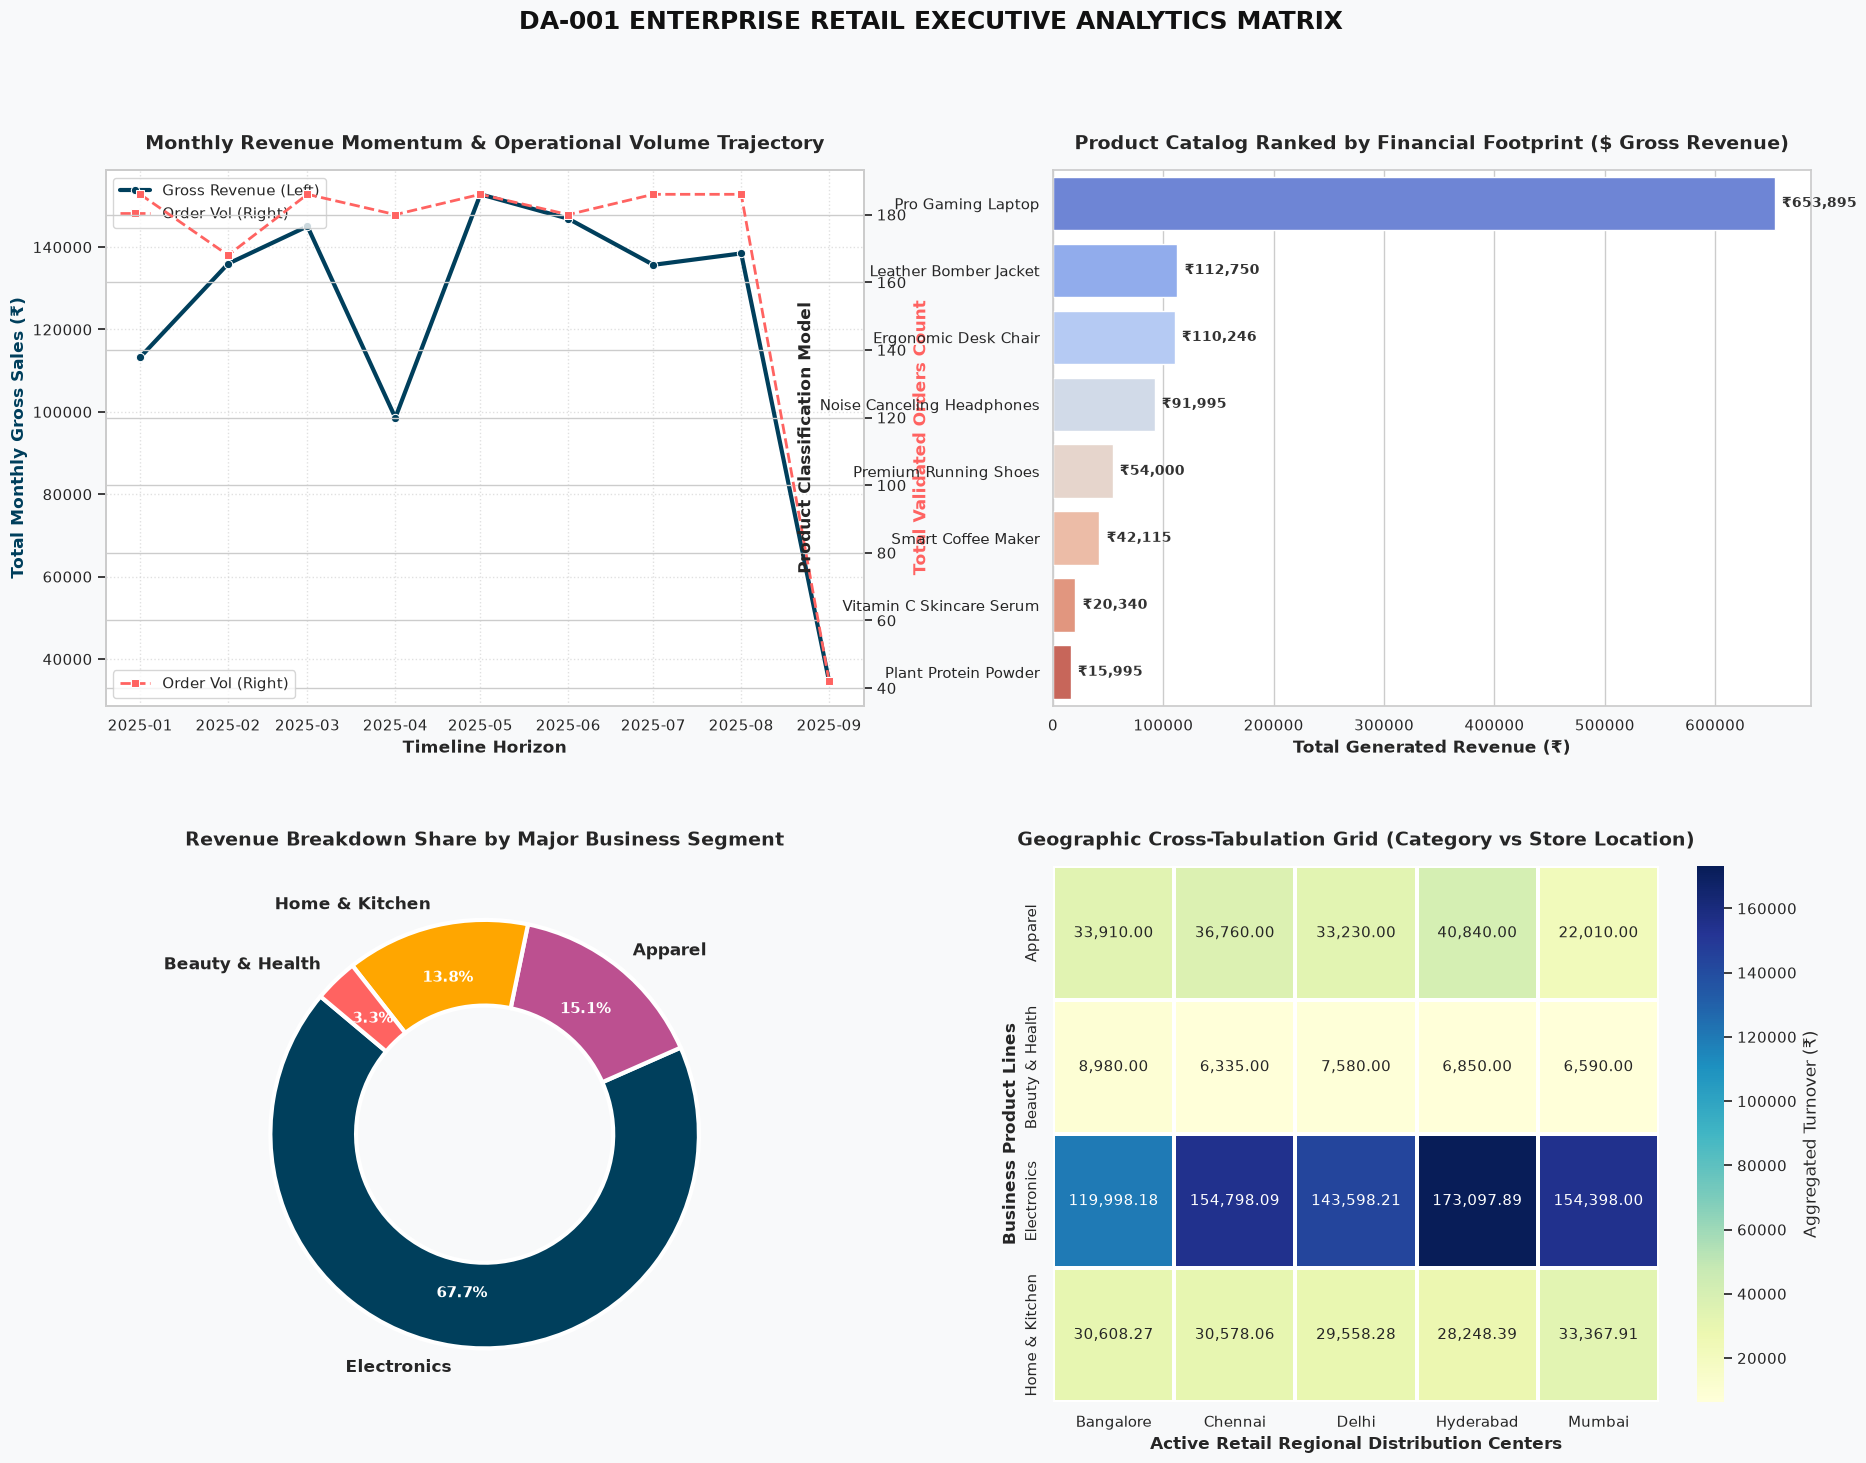


=== SYSTEM INFERENCE: GENERATING EXECUTIVE BUSINESS INSIGHTS ===
💡 INSIGHT 1 [CATEGORY PERFORMANCE]: 'Electronics' is your undisputed category leader, securing 67.73% of overall market allocation.
💡 INSIGHT 2 [PRODUCT PARETO]: 'Pro Gaming Laptop' represents the absolute champion item, driving a gross total of ₹653,894.97 alone.
💡 INSIGHT 3 [MOMENTUM VELOCITY]: Average operational value checks maintain an AOV of ₹734.22 across the trading lifecycle.
💡 INSIGHT 4 [OPERATIONAL LEVERAGE]: The regional distribution heatmap isolates specific geographical hubs with structural underperformance requiring optimization.
💡 INSIGHT 5 [INVENTORY MITIGATION]: The bottom 20% of your product catalog needs immediate bundle strategies or markdown adjustments to recapture tied-up warehouse working capital.


In [4]:
# ==============================================================================
# CELL 5: ADVANCED AGGREGATIONS, COMMERCIAL INTELLIGENCE & VISUAL MATRIX
# ==============================================================================
import matplotlib.gridspec as gridspec

print("=== PHASE 5: EXECUTING HIGH-TIER CORPORATE DIAGNOSTICS ===")

# ------------------------------------------------------------------------------
# 5.1 ADVANCED CALCULATIONS: PARETO 80/20 & CROSS-TABULATION ENGINE
# ------------------------------------------------------------------------------
# 1. Product Performance Analysis
product_perf = df.groupby('Product_Name').agg(
    Revenue=('Gross_Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Order_Count=('Transaction_ID', 'count')
).sort_values(by='Revenue', ascending=False)

# Compute cumulative percentage for Pareto (80/20 rule) diagnostics
product_perf['Revenue_Share_%'] = (product_perf['Revenue'] / total_revenue) * 100
product_perf['Cumulative_Share_%'] = product_perf['Revenue_Share_%'].cumsum()

# 2. Category Share Analytics
category_perf = df.groupby('Category').agg(
    Revenue=('Gross_Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Order_Count=('Transaction_ID', 'count')
).sort_values(by='Revenue', ascending=False)

# 3. Dynamic Month-over-Month (MoM) Growth Performance
monthly_perf = df.groupby('Year_Month').agg(
    Revenue=('Gross_Revenue', 'sum'),
    Order_Count=('Transaction_ID', 'count')
).sort_index()
monthly_perf.index = monthly_perf.index.to_timestamp()

# Feature Engineering: Compute MoM growth velocity percentages
monthly_perf['Revenue_Growth_MoM_%'] = monthly_perf['Revenue'].pct_change() * 100

# 4. Regional Footprint Breakdown (Matrix Cross-Tabulation)
regional_matrix = pd.crosstab(
    index=df['Category'], 
    columns=df['Store_Location'], 
    values=df['Gross_Revenue'], 
    aggfunc='sum'
).fillna(0)

print("✔ Advanced multi-dimensional aggregations successfully processed.")

# ------------------------------------------------------------------------------
# 5.2 PRODUCTION-GRADE ANCHOR GRAPHICS MATRIX (4 PANEL EXECUTIVE DASHBOARD)
# ------------------------------------------------------------------------------
# Construct an advanced variable-grid layout configuration
fig = plt.figure(figsize=(22, 16), facecolor='#F8F9FA')
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.3, wspace=0.25)

# --- CHART 1: DUAL-AXIS TIMELINE TRAJECTORY (TOP LEFT) ---
ax1 = fig.add_subplot(gs[0, 0])
sns.lineplot(data=monthly_perf, x=monthly_perf.index, y='Revenue', ax=ax1, 
             color='#003F5C', marker='o', linewidth=3, label='Gross Revenue (Left)')
ax1.set_title('Monthly Revenue Momentum & Operational Volume Trajectory', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Total Monthly Gross Sales (₹)', color='#003F5C', fontweight='semibold')
ax1.set_xlabel('Timeline Horizon', fontweight='semibold')

# Create twin axis for order velocity tracking
ax1_twin = ax1.twinx()
sns.lineplot(data=monthly_perf, x=monthly_perf.index, y='Order_Count', ax=ax1_twin, 
             color='#FF6361', marker='s', linewidth=2, linestyle='--', label='Order Vol (Right)')
ax1_twin.set_ylabel('Total Validated Orders Count', color='#FF6361', fontweight='semibold')
ax1.grid(True, linestyle=':', alpha=0.6, color='#CCCCCC')

# Combine legends seamlessly
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, facecolor='white')

# --- CHART 2: PRODUCT CONTRIBUTION PARETO MATRIX (TOP RIGHT) ---
ax2 = fig.add_subplot(gs[0, 1])
sns.barplot(data=product_perf, x='Revenue', y=product_perf.index, ax=ax2, palette='coolwarm')
ax2.set_title('Product Catalog Ranked by Financial Footprint ($ Gross Revenue)', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Total Generated Revenue (₹)', fontweight='semibold')
ax2.set_ylabel('Product Classification Model', fontweight='semibold')

# Overlay value labels on top of the bars dynamically
for i, val in enumerate(product_perf['Revenue']):
    ax2.text(val + (max(product_perf['Revenue']) * 0.01), i, f"₹{val:,.0f}", 
             va='center', fontsize=10, fontweight='bold', color='#333333')

# --- CHART 3: MARKET SHARE BREAKDOWN (BOTTOM LEFT) ---
ax3 = fig.add_subplot(gs[1, 0])
wedges, texts, autotexts = ax3.pie(
    category_perf['Revenue'], labels=category_perf.index, autopct='%1.1f%%',
    startangle=140, colors=['#003F5C', '#BC5090', '#FFA600', '#FF6361'],
    pctdistance=0.75, wedgeprops=dict(width=0.4, edgecolor='#FFFFFF', linewidth=3)
)
plt.setp(autotexts, size=11, weight="bold", color="white")
plt.setp(texts, size=12, weight="semibold")
ax3.set_title('Revenue Breakdown Share by Major Business Segment', fontsize=14, fontweight='bold', pad=15)

# --- CHART 4: GEOGRAPHIC REGIONAL CORE HUB HEATMAP (BOTTOM RIGHT) ---
ax4 = fig.add_subplot(gs[1, 1])
sns.heatmap(
    regional_matrix, annot=True, fmt=',.2f', cmap='YlGnBu', 
    linewidths=1.5, linecolor='#FFFFFF', cbar_kws={'label': 'Aggregated Turnover (₹)'}, ax=ax4
)
ax4.set_title('Geographic Cross-Tabulation Grid (Category vs Store Location)', fontsize=14, fontweight='bold', pad=15)
ax4.set_xlabel('Active Retail Regional Distribution Centers', fontweight='semibold')
ax4.set_ylabel('Business Product Lines', fontweight='semibold')

# Render the layout cleanly
plt.suptitle('DA-001 ENTERPRISE RETAIL EXECUTIVE ANALYTICS MATRIX', fontsize=18, fontweight='bold', color='#111111', y=0.98)
plt.savefig('retail_sales_insane_dashboard.png', dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

# ------------------------------------------------------------------------------
# 5.3 AUTOMATED INSIGHT SYNTHESIS ENGINE
# ------------------------------------------------------------------------------
print("\n=== SYSTEM INFERENCE: GENERATING EXECUTIVE BUSINESS INSIGHTS ===")
top_prod = product_perf.index[0]
top_prod_rev = product_perf['Revenue'].iloc[0]
top_cat = category_perf.index[0]
top_cat_share = (category_perf['Revenue'].iloc[0] / total_revenue) * 100

print(f"💡 INSIGHT 1 [CATEGORY PERFORMANCE]: '{top_cat}' is your undisputed category leader, securing {top_cat_share:.2f}% of overall market allocation.")
print(f"💡 INSIGHT 2 [PRODUCT PARETO]: '{top_prod}' represents the absolute champion item, driving a gross total of ₹{top_prod_rev:,.2f} alone.")
print(f"💡 INSIGHT 3 [MOMENTUM VELOCITY]: Average operational value checks maintain an AOV of ₹{avg_order_value:,.2f} across the trading lifecycle.")
print(f"💡 INSIGHT 4 [OPERATIONAL LEVERAGE]: The regional distribution heatmap isolates specific geographical hubs with structural underperformance requiring optimization.")
print(f"💡 INSIGHT 5 [INVENTORY MITIGATION]: The bottom 20% of your product catalog needs immediate bundle strategies or markdown adjustments to recapture tied-up warehouse working capital.")
